# Motor imagery EEG: complete analysis of nine participants

This notebook extends the supplied A01 analysis to **A01T–A09T** from BCI Competition IV 2a / BNCI 001-2014. It preserves the original coherence estimator, dissimilarity, seed-42 trial balancing, H0/H1 persistence and standard stable ranks. Duplicate A01 calculation cells have been replaced by reusable functions.

**Question:** Do imagined left-hand, right-hand, feet and tongue movements produce different topological signatures in frequency-specific EEG dependence networks, and are the patterns consistent across participants?

Run cells in order. The final cells contain executed results, plots and interpretation. The statistical unit for group analysis is the **participant (n = 9)**. The 20 trial selections are a sensitivity check, not 20 additional participants.

## 1. Setup
Install dependencies in the notebook's Python environment if needed:
```python
%pip install numpy scipy pandas matplotlib ripser nbformat nbclient ipykernel
```
All nine original training files are downloaded automatically if missing. You can change `DATA_DIR` to the folder already containing A01T.mat–A09T.mat. Keep the **T** sessions throughout; evaluation sessions are not used.

Official data page: https://bnci-horizon-2020.eu/database/data-sets

Direct links: [A01T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A01T.mat) | [A02T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A02T.mat) | [A03T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A03T.mat) | [A04T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A04T.mat) | [A05T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A05T.mat) | [A06T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A06T.mat) | [A07T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A07T.mat) | [A08T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A08T.mat) | [A09T.mat](https://lampx.tugraz.at/~bci/database/001-2014/A09T.mat)

In [1]:
from pathlib import Path
import os

DATA_DIR = Path(os.environ.get("EEG_DATA_DIR", str(Path.home() / "Downloads")))
OUTPUT_DIR = Path.cwd() / "results"
SUBJECTS = list(range(1, 10))
RUN_ANALYSIS = True       # False: display results already saved in OUTPUT_DIR
DOWNLOAD_MISSING = True
SAVE_EPOCHS = False      # True additionally saves the large prepared EEG arrays

print("Data:", DATA_DIR)
print("Results:", OUTPUT_DIR)

Data: /workspace/scratch/24213e33be81/data
Results: /workspace/scratch/24213e33be81/output/EEG_TDA_Project/results


## 2. Load and prepare each participant
Find blocks with trial markers rather than skipping a fixed number of calibration blocks (A04 differs). Convert MATLAB indices to Python indices. Extract samples [500, 1500) after each trial marker: the four seconds from cue onset until imagery ends. Keep the first 22 EEG columns; retain the three EOG columns for inspection only.

Exclude original artifact-marked or nonfinite trials. Stop and request inspection if an incomplete epoch or flat retained EEG channel is encountered. Review large amplitudes using a label-blind median/MAD rule; the main analysis **does not automatically remove** those review candidates. Preserve original block/trial IDs in an audit table.

In [2]:
from pathlib import Path
import hashlib
import json
import urllib.request
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import welch, csd, get_window
from scipy.stats import rankdata, friedmanchisquare
from scipy.sparse.csgraph import minimum_spanning_tree
from ripser import ripser

CLASS_NAMES = {1: "left_hand", 2: "right_hand", 3: "feet", 4: "tongue"}
MOVEMENTS = list(CLASS_NAMES.values())
BANDS = ["mu", "beta"]
NAMES = [f"{m}_{b}" for m in MOVEMENTS for b in BANDS]
CHANNELS = [f"EEG{i:02d}" for i in range(1, 23)]
COLORS = ["#007C91", "#C28E00", "#7C5BA7", "#D34B40"]
BASE_URL = "https://lampx.tugraz.at/~bci/database/001-2014/"
GRID = np.linspace(0, 1, 2001)
MAIN_SEED = 42
SELECTION_SEEDS = np.arange(100, 120)


def download_files(data_dir, subjects=range(1, 10)):
    """Download missing official training files, leaving existing files untouched."""
    data_dir = Path(data_dir).expanduser()
    data_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for subject in subjects:
        path = data_dir / f"A{subject:02d}T.mat"
        if not path.exists():
            print(f"Downloading {path.name}", flush=True)
            temporary = path.with_suffix(".mat.part")
            with urllib.request.urlopen(BASE_URL + path.name, timeout=120) as response:
                with temporary.open("wb") as out:
                    while chunk := response.read(1024 * 1024):
                        out.write(chunk)
            temporary.replace(path)
        paths.append(path)
    return paths


def prepare_subject(path):
    """Keep the original artifact/nonfinite policy; stop on incomplete/flat epochs.

    Original block and trial IDs remain zero-based. Amplitude flags are review
    candidates, NOT additional exclusions in the main analysis.
    """
    path = Path(path)
    runs = np.atleast_1d(loadmat(path, squeeze_me=True,
                               struct_as_record=False)["data"]).ravel()
    epochs, eyes, labels, ids, rows = [], [], [], [], []
    task_count = 0
    for block_id, run in enumerate(runs):
        markers = np.atleast_1d(run.trial).astype(int).ravel()
        if markers.size == 0:
            continue  # A04 has a different number of calibration blocks.
        task_count += 1
        fs = float(run.fs)
        if fs != 250 or run.X.shape[1] != 25:
            raise ValueError(f"Unexpected sampling rate/channel count: {path.name}")
        classes = [str(x).replace(" ", "_") for x in np.atleast_1d(run.classes)]
        if classes != MOVEMENTS:
            raise ValueError(f"Unexpected class order: {classes}")
        y = np.atleast_1d(run.y).astype(int).ravel()
        flags = np.atleast_1d(run.artifacts).astype(int).ravel()
        if not (len(markers) == len(y) == len(flags)):
            raise ValueError("Mismatched trial markers, labels or artifact flags")
        for trial_id, (marker, label, flag) in enumerate(zip(markers, y, flags)):
            start = int(marker) - 1 + 500
            stop = start + 1000
            if start < 0 or stop > len(run.X):
                raise ValueError(f"Incomplete epoch: {path.name}, {block_id}, {trial_id}")
            x = np.asarray(run.X[start:stop, :22], dtype=float)
            finite = bool(np.isfinite(x).all())
            keep = flag == 0 and finite
            reasons = []
            if flag != 0:
                reasons.append("dataset_artifact")
            if not finite:
                reasons.append("nonfinite_eeg")
            rows.append(dict(subject=path.stem, block=block_id, trial=trial_id,
                             label=int(label), movement=CLASS_NAMES[int(label)],
                             artifact_flag=int(flag), finite=finite, retained=keep,
                             exclusion_reason=";".join(reasons), review=False,
                             max_ptp_uv=float(np.ptp(x, axis=0).max()) if finite else np.nan))
            if keep:
                epochs.append(x)
                eyes.append(np.asarray(run.X[start:stop, 22:25], dtype=float))
                labels.append(label)
                ids.append((block_id, trial_id))
    X, y, ids = np.stack(epochs), np.asarray(labels), np.asarray(ids)
    if (np.ptp(X, axis=1) <= 1e-12).any():
        raise ValueError(f"Flat retained EEG channel in {path.name}; inspect before continuing")
    amp = np.ptp(X, axis=1).max(axis=1)
    med = np.median(amp)
    mad = np.median(np.abs(amp - med))
    cutoff = med + 6 * 1.4826 * mad
    review = amp > cutoff if mad > 0 else np.zeros(len(X), dtype=bool)
    for row, flag in zip([r for r in rows if r["retained"]], review):
        row["review"] = bool(flag)
    counts = [int((y == label).sum()) for label in CLASS_NAMES]
    if min(counts) < 2:
        raise ValueError(f"Too few usable trials: {path.name}")
    return dict(subject=path.stem, path=path, X=X, eog=np.stack(eyes), y=y, ids=ids,
                fs=250., audit=pd.DataFrame(rows), review=review, cutoff=float(cutoff),
                counts=counts, n_blocks=len(runs), n_task_blocks=task_count,
                sha256=hashlib.sha256(path.read_bytes()).hexdigest())

## 3. Estimate spectral dependence
Use 1-second periodic Hann windows with 50% overlap: seven windows per trial and 1-Hz frequency bins. Remove each window's constant mean. Average complex cross spectra and auto spectra across trials of one movement before computing magnitude-squared coherence.

For each EEG pair, band-average coherence over mu (8–12 Hz bins) or beta (13–30 Hz bins), then calculate D = 1 − C. Cache per-trial spectral estimates so the exact same estimator can be reused efficiently for 20 selections. This optimization was checked against the original notebook to numerical precision.

No extra filtering, re-referencing, ICA, z-scoring or trial-amplitude normalization is introduced. A fixed channel multiplier cancels from coherence; this does not remove subject differences, eye artifacts, reference effects or volume conduction.

In [3]:
def spectral_options(fs):
    n = int(fs)
    return dict(fs=fs, window=get_window("hann", n, fftbins=True), nperseg=n,
                noverlap=n // 2, nfft=n, detrend="constant", scaling="density",
                average="mean", axis=1)


def spectral_cache(X, fs):
    """One complex spectral matrix per trial and frequency, using original Welch settings.

    Retain only 8-30 Hz after estimation; this is frequency selection, not an
    added time-domain filter. Seven 1-s windows per 4-s trial, with 50% overlap.
    """
    options = spectral_options(fs)
    frequencies, auto = welch(X, **options)
    mask = (frequencies >= 8) & (frequencies <= 30)
    auto = auto[:, mask]
    if not np.isfinite(auto).all() or np.any(auto <= 0):
        raise ValueError("Invalid or zero spectral power")
    S = np.empty((len(X), mask.sum(), 22, 22), dtype=np.complex128)
    for i in range(22):
        S[:, :, i, i] = auto[:, :, i]
        for j in range(i + 1, 22):
            _, cross = csd(X[:, :, i], X[:, :, j], **options)
            S[:, :, i, j] = cross[:, mask]
            S[:, :, j, i] = cross[:, mask].conj()
    return frequencies[mask], S


def matrices_from_cache(frequencies, spectra, labels, indices):
    results = {}
    for label, movement in CLASS_NAMES.items():
        chosen = indices[labels[indices] == label]
        if len(chosen) < 2:
            raise ValueError(f"Too few trials for {movement}")
        pooled = spectra[chosen].mean(axis=0)  # complex average BEFORE magnitude
        power = np.diagonal(pooled, axis1=1, axis2=2).real
        coherence = np.abs(pooled) ** 2 / (power[:, :, None] * power[:, None, :])
        if not np.isfinite(coherence).all() or coherence.max() > 1 + 1e-10:
            raise ValueError("Invalid coherence")
        coherence = np.clip(coherence, 0, 1)
        for band, mask in {"mu": (frequencies >= 8) & (frequencies < 13),
                           "beta": (frequencies >= 13) & (frequencies <= 30)}.items():
            C = coherence[mask].mean(axis=0)
            C = (C + C.T) / 2
            np.fill_diagonal(C, 1)
            D = 1 - C
            np.fill_diagonal(D, 0)
            assert D.shape == (22, 22) and np.isfinite(D).all()
            assert np.allclose(D, D.T) and np.all((D >= 0) & (D <= 1))
            results[f"{movement}_{band}"] = dict(coherence=C, distance=D, n_trials=len(chosen))
    return results


def balanced_indices(labels, n_each, seed):
    rng = np.random.default_rng(int(seed))
    return np.sort(np.concatenate([
        rng.choice(np.flatnonzero(labels == c), n_each, replace=False)
        for c in CLASS_NAMES
    ]))

## 4. Topological analysis
Each of the 22 channels is a vertex. At threshold epsilon, connect pairs with D ≤ epsilon and fill every clique, including triangles. This weighted flag filtration is well defined even when D violates the triangle inequality.

Compute H0 (components) and H1 (unfilled loops) over F2 up to threshold 1. Retain the one infinite H0 interval. The standard stable rank counts bars with `death - birth > t`; t is a lifespan cutoff, not time in seconds. Compute L1 distances between curves exactly at every jump. For scalar total persistence, omit the infinite interval and sum finite lifespans; equivalently integrate R_H0 − 1 or R_H1.

In [4]:
def persistence(matrices):
    diagrams = {}
    for name, item in matrices.items():
        D = item["distance"]
        dgms = ripser(D, distance_matrix=True, maxdim=1, thresh=1.0, coeff=2)["dgms"]
        assert len(dgms[0]) == 22 and np.isinf(dgms[0][:, 1]).sum() == 1
        assert np.isfinite(dgms[1]).all()
        # Independent H0 check: finite deaths equal minimum-spanning-tree weights.
        deaths = np.sort(dgms[0][np.isfinite(dgms[0][:, 1]), 1])
        assert np.allclose(deaths, np.sort(minimum_spanning_tree(D).data), atol=1e-7)
        diagrams[name] = dgms
    return diagrams


def stable_rank(diagram, grid):
    lengths = diagram[:, 1] - diagram[:, 0]
    return (lengths[:, None] > np.asarray(grid)[None, :]).sum(axis=0)


def finite_lifetimes(diagram):
    return (diagram[:, 1] - diagram[:, 0])[np.isfinite(diagram[:, 1])]


def exact_rank_l1(a, b):
    """Exact integral of |R_a - R_b|; equal infinite tails cancel."""
    if np.isinf(a[:, 1]).sum() != np.isinf(b[:, 1]).sum():
        return np.inf
    lengths = np.r_[finite_lifetimes(a), finite_lifetimes(b)]
    grid = np.unique(np.r_[0., lengths, 1.])
    area = np.sum(np.abs(stable_rank(a, grid)[:-1] - stable_rank(b, grid)[:-1]) * np.diff(grid))
    return float(area)


def pairwise_rank_distances(ph):
    result = {}
    for band in BANDS:
        for dim in [0, 1]:
            M = np.zeros((4, 4))
            for i in range(4):
                for j in range(i + 1, 4):
                    M[i, j] = M[j, i] = exact_rank_l1(ph[f"{MOVEMENTS[i]}_{band}"][dim],
                                                    ph[f"{MOVEMENTS[j]}_{band}"][dim])
            result[f"{band}_H{dim}"] = M
    return result


def feature_rows(ph, subject, analysis):
    rows = []
    for name, dgms in ph.items():
        movement, band = name.rsplit("_", 1)
        for dim, dgm in enumerate(dgms):
            lengths = finite_lifetimes(dgm)
            rows.append(dict(subject=subject, analysis=analysis, movement=movement, band=band,
                             homology=f"H{dim}", finite_bars=len(lengths),
                             total_persistence=float(lengths.sum()),
                             longest_lifespan=float(lengths.max(initial=0)),
                             stable_rank_005=int(stable_rank(dgm, [0.05])[0]),
                             stable_rank_010=int(stable_rank(dgm, [0.10])[0])))
    return rows


def save_topology(folder, prefix, matrices, ph, ids, labels, indices, n_each, seed):
    arrays = dict(selected_indices=indices, trial_ids=ids[indices], labels=labels[indices],
                  trials_per_movement=n_each, seed=seed, lifespan_grid=GRID)
    for name in NAMES:
        arrays[f"C_{name}"] = matrices[name]["coherence"]
        arrays[f"D_{name}"] = matrices[name]["distance"]
        for dim in [0, 1]:
            arrays[f"H{dim}_{name}"] = ph[name][dim]
            arrays[f"SR_H{dim}_{name}"] = stable_rank(ph[name][dim], GRID)
    arrays.update({f"L1_{key}": value for key, value in pairwise_rank_distances(ph).items()})
    np.savez_compressed(folder / f"{prefix}.npz", **arrays)

## 5. Quality-control and topology plots
Save amplitude review, EEG/EOG inspection, channel matrices, barcodes, stable ranks and repeated-selection plots for every participant. Vertical EEG offsets in the inspection plots are display adjustments only. Channel names EEG01–EEG22 refer to column order, not anatomical labels.

In [5]:
def save_figure(fig, path):
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def plot_quality(p, folder):
    amp = np.ptp(p["X"], axis=1).max(axis=1)
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    ax.plot(amp, ".", color=COLORS[0])
    ax.axhline(p["cutoff"], ls="--", color=COLORS[3], label="Review threshold")
    ax.set(xlabel="Retained trial index (0-based)", ylabel="Maximum channel peak-to-peak (microvolts)",
           title=f"{p['subject']}: amplitude review; flagged trials remain in main analysis")
    ax.legend()
    save_figure(fig, folder / "quality_review.png")
    # Save every flagged trial and the largest trial for inspection.
    for k in np.unique(np.r_[np.flatnonzero(p["review"]), amp.argmax()]):
        x = p["X"][k] - p["X"][k].mean(axis=0)
        t = np.arange(1000) / p["fs"]
        spacing = max(60., amp[k] * 1.2)
        fig, axes = plt.subplots(1, 2, figsize=(12, 7), layout="constrained")
        offsets = np.arange(22)[::-1] * spacing
        axes[0].plot(t, x + offsets, lw=.5)
        axes[0].set_yticks(offsets, CHANNELS, fontsize=7)
        axes[0].set(xlabel="Seconds after cue", title="EEG, centered and offset for display")
        axes[1].plot(t, p["eog"][k], lw=.6)
        axes[1].legend(["EOG1", "EOG2", "EOG3"])
        axes[1].set(xlabel="Seconds after cue", ylabel="Microvolts", title="Eye signals from the same trial")
        fig.suptitle(f"{p['subject']}: original (block, trial) = {tuple(p['ids'][k])}")
        save_figure(fig, folder / f"review_trial_{k:03d}.png")


def plot_matrices(matrices, subject, folder):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
    for r, band in enumerate(BANDS):
        for c, movement in enumerate(MOVEMENTS):
            ax = axes[r, c]
            im = ax.imshow(matrices[f"{movement}_{band}"]["distance"], vmin=0, vmax=1, cmap="viridis")
            ax.set(title=f"{movement.replace('_', ' ')} | {band}", xlabel="EEG index", ylabel="EEG index")
    fig.colorbar(im, ax=axes, shrink=.8, label="D = 1 - coherence")
    fig.suptitle(f"{subject}: balanced channel dissimilarities")
    save_figure(fig, folder / "balanced_distances.png")


def plot_barcodes(ph, subject, folder):
    finite_deaths = [d[np.isfinite(d[:, 1]), 1].max(initial=0) for ds in ph.values() for d in ds]
    limit = min(1., max(.1, np.ceil(max(finite_deaths) * 1.1 * 20) / 20))
    for band in BANDS:
        fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
        for c, movement in enumerate(MOVEMENTS):
            for dim in [0, 1]:
                dgm = ph[f"{movement}_{band}"][dim]
                ax = axes[dim, c]
                for row, (birth, death) in enumerate(dgm[np.argsort(dgm[:, 0], kind="stable")]):
                    ax.hlines(row, birth, limit if np.isinf(death) else death,
                              color=COLORS[dim], lw=2)
                    if np.isinf(death):
                        ax.plot(limit, row, ">", color=COLORS[dim], clip_on=False)
                ax.set(xlim=(0, limit), ylim=(-1, max(len(dgm), 1)), yticks=[],
                       xlabel="Distance threshold", title=f"{movement.replace('_', ' ')}: H{dim}")
        fig.suptitle(f"{subject}: {band} barcodes; arrow = infinite H0 interval")
        save_figure(fig, folder / f"barcodes_{band}.png")


def plot_ranks(ph, subject, folder, selection=None):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    limit = max(.1, 1.1 * max(finite_lifetimes(d).max(initial=0) for ds in ph.values() for d in ds))
    for col, band in enumerate(BANDS):
        for dim in [0, 1]:
            ax = axes[dim, col]
            for movement, color in zip(MOVEMENTS, COLORS):
                name = f"{movement}_{band}"
                if selection is None:
                    grid = np.unique(np.r_[0, finite_lifetimes(ph[name][dim]), 1])
                    ax.step(grid, stable_rank(ph[name][dim], grid), where="post", color=color,
                            label=movement.replace("_", " "), lw=1.7)
                else:
                    v = selection[name][:, dim]
                    ax.step(GRID, np.median(v, axis=0), where="post", color=color,
                            label=movement.replace("_", " "), lw=1.7)
                    ax.fill_between(GRID, v.min(axis=0), v.max(axis=0), step="post", color=color, alpha=.18)
            ax.set(xlim=(0, limit), ylim=(0, None), title=f"{band} band: H{dim}",
                   xlabel="Minimum bar lifespan", ylabel="Stable rank")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
    title = "standard stable ranks; infinite H0 retained" if selection is None else "20 selections: median and observed min-max (not a CI)"
    fig.suptitle(f"{subject}: {title}")
    save_figure(fig, folder / ("stable_ranks.png" if selection is None else "selection_sensitivity.png"))

## 6. Run the complete within-participant workflow
Keep equal numbers from the four movements using the smallest retained class count for that participant (seed 42). Repeat with seeds 100–119, without replacement within each selection. Save selected trial IDs, curves and exact distances from the primary curves. Min–max shading is an observed sensitivity range, not a confidence interval.

Also recompute matrices temporarily without amplitude-review candidates and report the mean and maximum absolute change over the 231 unique EEG pairs. This is a sensitivity scenario, not a definitive artifact-cleaned analysis. Finally, repeat topology with the common minimum count across all participants (49 per movement in these files).

In [6]:
def analyse_subject(path, output_root, common_n, save_epochs=False):
    p = prepare_subject(path)
    sid = p["subject"]
    folder = Path(output_root) / sid
    folder.mkdir(parents=True, exist_ok=True)
    p["audit"].to_csv(folder / "trial_audit.csv", index=False)
    if save_epochs:
        np.savez_compressed(folder / "prepared_epochs.npz", epochs=p["X"], eog=p["eog"],
                            labels=p["y"], trial_ids=p["ids"], fs=p["fs"])
    f, S = spectral_cache(p["X"], p["fs"])
    all_indices = np.arange(len(p["y"]))
    all_matrices = matrices_from_cache(f, S, p["y"], all_indices)
    np.savez_compressed(folder / "all_retained_distances.npz",
                        **{f"{key}_{name}": item[field] for name, item in all_matrices.items()
                           for key, field in [("C", "coherence"), ("D", "distance")]})
    sensitivity_rows = []
    without = all_matrices
    if p["review"].any():
        without = matrices_from_cache(f, S, p["y"], all_indices[~p["review"]])
    for name in NAMES:
        delta = np.abs(all_matrices[name]["distance"] - without[name]["distance"])[np.triu_indices(22, 1)]
        sensitivity_rows.append(dict(subject=sid, matrix=name, n_review=int(p["review"].sum()),
                                     mean_change=float(delta.mean()), max_change=float(delta.max())))
    pd.DataFrame(sensitivity_rows).to_csv(folder / "amplitude_sensitivity.csv", index=False)
    n_each = min(p["counts"])
    idx = balanced_indices(p["y"], n_each, MAIN_SEED)
    matrices = matrices_from_cache(f, S, p["y"], idx)
    ph = persistence(matrices)
    save_topology(folder, "balanced_topology", matrices, ph, p["ids"], p["y"], idx, n_each, MAIN_SEED)
    for name, item in matrices.items():
        pd.DataFrame(item["distance"], index=CHANNELS, columns=CHANNELS).to_csv(folder / f"D_{name}.csv")
    features = feature_rows(ph, sid, "main")
    selection = {name: np.empty((len(SELECTION_SEEDS), 2, len(GRID)), dtype=np.int16) for name in NAMES}
    selection_ids, selection_features, selection_l1 = [], [], []
    for repeat, seed in enumerate(SELECTION_SEEDS):
        chosen = balanced_indices(p["y"], n_each, seed)
        selection_ids.append(chosen)
        repeat_ph = persistence(matrices_from_cache(f, S, p["y"], chosen))
        for name in NAMES:
            for dim in [0, 1]:
                selection[name][repeat, dim] = stable_rank(repeat_ph[name][dim], GRID)
                selection_l1.append(dict(subject=sid, seed=int(seed), matrix=name, homology=f"H{dim}",
                                         l1_to_main=exact_rank_l1(ph[name][dim], repeat_ph[name][dim])))
        for row in feature_rows(repeat_ph, sid, "selection"):
            row["seed"] = int(seed)
            selection_features.append(row)
    np.savez_compressed(folder / "selection_sensitivity.npz", seeds=SELECTION_SEEDS,
                        selected_indices=np.stack(selection_ids), trial_ids=p["ids"][np.stack(selection_ids)],
                        lifespan_grid=GRID, trials_per_movement=n_each,
                        **{f"SR_{name}": v for name, v in selection.items()})
    pd.DataFrame(selection_features).to_csv(folder / "selection_features.csv", index=False)
    pd.DataFrame(selection_l1).to_csv(folder / "selection_l1_to_main.csv", index=False)
    common_idx = balanced_indices(p["y"], common_n, MAIN_SEED)
    common_matrices = matrices_from_cache(f, S, p["y"], common_idx)
    common_ph = persistence(common_matrices)
    save_topology(folder, "common_count_topology", common_matrices, common_ph, p["ids"], p["y"],
                  common_idx, common_n, MAIN_SEED)
    features += feature_rows(common_ph, sid, "common_count")
    pd.DataFrame(features).to_csv(folder / "topology_features.csv", index=False)
    settings = dict(source_url=BASE_URL + path.name, sha256=p["sha256"], fs=250,
                    sample_window_after_trial_marker=[500, 1500], seconds_after_trial_marker=[2, 6],
                    eeg_columns="0-21", eog_columns="22-24 (review only)",
                    reference="original left mastoid", added_filter="none", normalization="none",
                    detrending="subtract each Welch window mean", window="periodic Hann",
                    nperseg=250, noverlap=125, nfft=250, windows_per_trial=7,
                    bands={"mu": "8 <= f < 13", "beta": "13 <= f <= 30"},
                    spectral_pooling="complex cross spectra and auto spectra averaged over trials before coherence",
                    main_seed=MAIN_SEED, selection_seeds=SELECTION_SEEDS.tolist(),
                    primary_n_each=n_each, common_n_each=common_n,
                    review_cutoff_uv=p["cutoff"], review_original_ids=p["ids"][p["review"]].tolist(),
                    review_rule="median + 6 * 1.4826 * MAD; review only",
                    filtration="weighted flag complex; D=1-bandmean magnitude-squared coherence",
                    maxdim=1, coeff=2, threshold=1.0,
                    stable_rank="count death-birth > t; infinite H0 retained",
                    total_persistence="sum of finite lifetimes (infinite H0 omitted only from scalar area)",
                    versions={pkg: importlib.metadata.version(pkg) for pkg in ["numpy", "scipy", "ripser", "matplotlib", "pandas"]})
    (folder / "settings.json").write_text(json.dumps(settings, indent=2))
    plot_quality(p, folder)
    plot_matrices(matrices, sid, folder)
    plot_barcodes(ph, sid, folder)
    plot_ranks(ph, sid, folder)
    plot_ranks(ph, sid, folder, selection)
    summary = dict(subject=sid, blocks=p["n_blocks"], task_blocks=p["n_task_blocks"],
                   original=len(p["audit"]), excluded=len(p["audit"]) - len(p["y"]), retained=len(p["y"]),
                   **dict(zip(MOVEMENTS, p["counts"])), balanced_each=n_each,
                   balanced_total=4*n_each, review_candidates=int(p["review"].sum()))
    print(f"{sid}: retained {summary['retained']}; {n_each}/movement; 20 selections finished", flush=True)
    return summary

## 7. Compare participants
Compare within-participant movement distances, paired finite total persistence and the direction of movement contrasts. For each of the four band/homology combinations, run an exploratory Friedman rank statistic calibrated by 99,999 random permutations of movement labels **within each participant**, then apply Holm correction across the four primary tests. The null requires within-participant label exchangeability. These tests concern finite total persistence, not every property of the full barcode.

The common-count analysis repeats the same four tests as a sensitivity check, with its own Holm adjustment. The feet/tongue-minus-hands contrast is descriptive and was motivated by the earlier A01 plot; it is not a pre-specified confirmatory test. No classifier or held-out accuracy is estimated.

In [7]:
def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues)
    order = np.argsort(pvalues)
    adjusted = np.empty_like(pvalues)
    adjusted[order] = np.minimum(1., np.maximum.accumulate(pvalues[order] * np.arange(len(order), 0, -1)))
    return adjusted


def permutation_friedman(values, n_permutations=99999, seed=2026):
    """Monte Carlo within-participant label permutations; no chi-square approximation.

    Tests exchangeability of the four movement summaries within participants.
    Uses one finite total-persistence summary per participant/movement.
    """
    values = np.asarray(values, float)
    n, k = values.shape
    ranks = rankdata(values, axis=1)
    ties = sum(sum(c**3-c for c in np.unique(row, return_counts=True)[1]) for row in values)
    correction = 1 - ties / (n * (k**3-k))
    if correction <= 0:
        return 0., 1., 0.
    def statistic(rank_sums):
        return (12 / (n*k*(k+1)) * np.square(rank_sums).sum(axis=-1) - 3*n*(k+1)) / correction
    observed = float(statistic(ranks.sum(axis=0)))
    assert np.isclose(observed, friedmanchisquare(*values.T).statistic)
    rng = np.random.default_rng(seed)
    exceed = 0
    for start in range(0, n_permutations, 1000):
        b = min(1000, n_permutations-start)
        permutations = np.argsort(rng.random((b, n, k)), axis=-1)
        shuffled = np.take_along_axis(np.broadcast_to(ranks, (b,n,k)), permutations, axis=2)
        exceed += int((statistic(shuffled.sum(axis=1)) >= observed - 1e-10).sum())
    p = (exceed + 1) / (n_permutations + 1)
    return observed, float(p), float(np.sqrt(p*(1-p)/(n_permutations+1)))


def group_analysis(output_root, subjects):
    root = Path(output_root)
    folders = [root / sid for sid in subjects]
    features = pd.concat([pd.read_csv(f / "topology_features.csv") for f in folders], ignore_index=True)
    features.to_csv(root / "all_topology_features.csv", index=False)
    amplitude = pd.concat([pd.read_csv(f / "amplitude_sensitivity.csv") for f in folders], ignore_index=True)
    amplitude.to_csv(root / "all_amplitude_sensitivity.csv", index=False)
    selections = pd.concat([pd.read_csv(f / "selection_features.csv") for f in folders], ignore_index=True)
    selections.to_csv(root / "all_selection_features.csv", index=False)
    l1_variation = pd.concat([pd.read_csv(f / "selection_l1_to_main.csv") for f in folders], ignore_index=True)
    l1_variation.to_csv(root / "all_selection_l1.csv", index=False)
    tests = []
    for analysis in ["main", "common_count"]:
        these = []
        for band in BANDS:
            for homology in ["H0", "H1"]:
                frame = features.query("analysis == @analysis and band == @band and homology == @homology")
                values = frame.pivot(index="subject", columns="movement", values="total_persistence").loc[subjects, MOVEMENTS].values
                stat, p, mcse = permutation_friedman(values)
                these.append(dict(analysis=analysis, band=band, homology=homology, n_subjects=len(subjects),
                                  friedman_Q=stat, kendall_W=stat/(len(subjects)*3), permutation_p=p,
                                  monte_carlo_se=mcse, permutations=99999, seed=2026))
        for row, adjusted in zip(these, holm_adjust([r["permutation_p"] for r in these])):
            row["holm_p"] = float(adjusted)
        tests.extend(these)
    tests = pd.DataFrame(tests)
    tests.to_csv(root / "exploratory_omnibus_tests.csv", index=False)
    main = features.query("analysis == 'main'")
    group_summary = main.groupby(["band", "homology", "movement"]).agg(
        median_total=("total_persistence", "median"), min_total=("total_persistence", "min"),
        max_total=("total_persistence", "max"), median_longest=("longest_lifespan", "median"),
        median_finite_bars=("finite_bars", "median")).reset_index()
    group_summary.to_csv(root / "group_feature_summary.csv", index=False)
    pair_rows = []
    loaded = {sid: np.load(root / sid / "balanced_topology.npz") for sid in subjects}
    for sid in subjects:
        for band in BANDS:
            for dim in [0, 1]:
                M = loaded[sid][f"L1_{band}_H{dim}"]
                for i in range(4):
                    for j in range(i+1, 4):
                        pair_rows.append(dict(subject=sid, band=band, homology=f"H{dim}",
                                              movement_1=MOVEMENTS[i], movement_2=MOVEMENTS[j], l1=M[i,j]))
    pairs = pd.DataFrame(pair_rows)
    pairs.to_csv(root / "within_subject_pairwise_l1.csv", index=False)
    pairs.groupby(["band","homology","movement_1","movement_2"]).l1.agg(["median","min","max"]).reset_index().to_csv(root / "group_pairwise_l1_summary.csv", index=False)
    # A01-generated descriptive pattern, not a pre-specified confirmatory hypothesis.
    contrasts = []
    for analysis in ["main", "common_count"]:
        for band in BANDS:
            for homology in ["H0", "H1"]:
                x = features.query("analysis == @analysis and band == @band and homology == @homology")
                v = x.pivot(index="subject", columns="movement", values="total_persistence").loc[subjects]
                difference = v[["feet","tongue"]].mean(axis=1)-v[["left_hand","right_hand"]].mean(axis=1)
                for sid, value in difference.items():
                    contrasts.append(dict(subject=sid, analysis=analysis, band=band, homology=homology,
                                          feet_tongue_minus_hands=float(value)))
    pd.DataFrame(contrasts).to_csv(root / "exploratory_direction_contrasts.csv", index=False)
    # Paired features: each grey line belongs to one participant.
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for col, band in enumerate(BANDS):
        for dim in [0,1]:
            h=f"H{dim}"
            v=main.query("band == @band and homology == @h").pivot(index="subject", columns="movement", values="total_persistence").loc[subjects,MOVEMENTS]
            ax=axes[dim,col]
            ax.plot(np.arange(4), v.values.T, color="#9AA4B0", alpha=.75, lw=.9, marker=".")
            ax.plot(np.arange(4), v.median(axis=0), color="#172C49", lw=2.5, marker="o", label="Across-participant median")
            ax.set_xticks(range(4),["Left hand","Right hand","Feet","Tongue"])
            ax.set(title=f"{band}: {h}", ylabel="Sum of finite bar lifespans")
            ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle("Paired total persistence: each grey line is one participant (n = 9)")
    save_figure(fig, root / "group_total_persistence.png")
    # Median of within-participant distances, not distance between averaged EEG.
    fig, axes=plt.subplots(2,2,figsize=(9,8),layout="constrained")
    for col,band in enumerate(BANDS):
        for dim in [0,1]:
            ax=axes[dim,col]
            M=np.median(np.stack([loaded[s][f"L1_{band}_H{dim}"] for s in subjects]),axis=0)
            im=ax.imshow(M,cmap="Blues",vmin=0)
            for i in range(4):
                for j in range(4):ax.text(j,i,f"{M[i,j]:.3f}",ha="center",va="center",color="white" if M[i,j]>M.max()*.65 else "#152238")
            ax.set_xticks(range(4),["Left","Right","Feet","Tongue"])
            ax.set_yticks(range(4),["Left","Right","Feet","Tongue"])
            ax.set_title(f"{band}: H{dim}")
            fig.colorbar(im,ax=ax,shrink=.8)
    fig.suptitle("Median within-participant L1 distance between stable-rank curves")
    save_figure(fig,root / "group_pairwise_distances.png")
    # All participants on identical scales, by band and homology.
    for band in BANDS:
        for dim in [0,1]:
            xmax=max(.1,1.05*max(finite_lifetimes(loaded[s][f"H{dim}_{m}_{band}"]).max(initial=0) for s in subjects for m in MOVEMENTS))
            ymax=max(stable_rank(loaded[s][f"H{dim}_{m}_{band}"],[0])[0] for s in subjects for m in MOVEMENTS)
            fig,axes=plt.subplots(3,3,figsize=(12,8),layout="constrained",sharex=True,sharey=True)
            for ax,sid in zip(axes.ravel(),subjects):
                for m,color in zip(MOVEMENTS,COLORS):
                    dgm=loaded[sid][f"H{dim}_{m}_{band}"]
                    g=np.unique(np.r_[0,finite_lifetimes(dgm),1])
                    ax.step(g,stable_rank(dgm,g),where="post",color=color,label=m.replace('_',' '),lw=1.4)
                ax.set(title=sid, xlim=(0,xmax),ylim=(0,ymax+1));ax.grid(alpha=.18)
            axes[0,0].legend(fontsize=7)
            fig.supxlabel("Minimum bar lifespan");fig.supylabel("Stable rank")
            fig.suptitle(f"{band} band, H{dim}: all nine participants")
            save_figure(fig,root/f"all_subjects_{band}_H{dim}.png")
    for z in loaded.values():z.close()
    return features, tests, pairs


def run_all(data_dir, output_root, subjects=range(1,10), download_missing=True, save_epochs=False):
    output_root=Path(output_root)
    output_root.mkdir(parents=True,exist_ok=True)
    paths=download_files(data_dir,subjects) if download_missing else [Path(data_dir)/f"A{i:02d}T.mat" for i in subjects]
    missing=[str(p) for p in paths if not p.exists()]
    if missing:raise FileNotFoundError("Missing files: "+", ".join(missing))
    # First pass determines the common sample size using quality exclusions only.
    min_counts=[]
    for path in paths:
        prepared=prepare_subject(path)
        min_counts.append(min(prepared["counts"]))
        del prepared
    common_n=min(min_counts)
    print(f"Common-count sensitivity: {common_n} trials per movement for every participant",flush=True)
    summaries=[]
    for path in paths:
        summaries.append(analyse_subject(path,output_root,common_n,save_epochs))
        pd.DataFrame(summaries).to_csv(output_root/"participant_summary.csv",index=False)
    features,tests,pairs=group_analysis(output_root,[p.stem for p in paths])
    return pd.DataFrame(summaries),features,tests,pairs

## 8. Execute all nine participants
This cell saves a separate folder per participant and pooled **summary tables**. EEG traces are never pooled across participants.

In [8]:
if RUN_ANALYSIS:
    participant_summary, features, omnibus_tests, pairwise_distances = run_all(
        DATA_DIR, OUTPUT_DIR, subjects=SUBJECTS,
        download_missing=DOWNLOAD_MISSING, save_epochs=SAVE_EPOCHS
    )
else:
    participant_summary = pd.read_csv(OUTPUT_DIR / "participant_summary.csv")
    features = pd.read_csv(OUTPUT_DIR / "all_topology_features.csv")
    omnibus_tests = pd.read_csv(OUTPUT_DIR / "exploratory_omnibus_tests.csv")
    pairwise_distances = pd.read_csv(OUTPUT_DIR / "within_subject_pairwise_l1.csv")

display(participant_summary)
print("Original trials:", participant_summary.original.sum())
print("Retained trials:", participant_summary.retained.sum())
print("Balanced main-analysis trials:", participant_summary.balanced_total.sum())

Common-count sensitivity: 49 trials per movement for every participant
A01T: retained 273; 67/movement; 20 selections finished
A02T: retained 270; 66/movement; 20 selections finished
A03T: retained 270; 66/movement; 20 selections finished
A04T: retained 262; 62/movement; 20 selections finished
A05T: retained 262; 63/movement; 20 selections finished
A06T: retained 219; 49/movement; 20 selections finished
A07T: retained 271; 66/movement; 20 selections finished
A08T: retained 264; 64/movement; 20 selections finished
A09T: retained 237; 53/movement; 20 selections finished
Original trials: 2592
Retained trials: 2328
Balanced main-analysis trials: 2224


,subject,blocks,task_blocks,original,excluded,retained,left_hand,right_hand,feet,tongue,balanced_each,balanced_total,review_candidates
0,A01T,9,6,288,15,273,69,69,68,67,67,268,1
1,A02T,9,6,288,18,270,67,69,66,68,66,264,2
2,A03T,9,6,288,18,270,69,68,66,67,66,264,0
3,A04T,7,6,288,26,262,62,67,67,66,62,248,0
4,A05T,9,6,288,26,262,63,66,66,67,63,252,0
5,A06T,9,6,288,69,219,56,57,49,57,49,196,0
6,A07T,9,6,288,17,271,67,66,67,71,66,264,6
7,A08T,9,6,288,24,264,66,66,64,68,64,256,0
8,A09T,9,6,288,51,237,53,63,61,60,53,212,0


## 9. Group results
Lower finite H0 total persistence means the sensor network merges at smaller dissimilarity thresholds. Higher H1 total persistence reflects more and/or longer-lived loops. Neither alone measures greater brain activation.

,analysis,band,homology,n_subjects,friedman_Q,kendall_W,permutation_p,monte_carlo_se,permutations,seed,holm_p
0,main,mu,H0,9,4.333333,0.160494,0.24550,0.001361,99999,2026,0.98156
1,main,mu,H1,9,0.866667,0.032099,0.85155,0.001124,99999,2026,1.00000
2,main,beta,H0,9,4.333333,0.160494,0.24539,0.001361,99999,2026,0.98156
3,main,beta,H1,9,0.733333,0.027160,0.88637,0.001004,99999,2026,1.00000
4,common_count,mu,H0,9,3.933333,0.145679,0.29005,0.001435,99999,2026,1.00000
5,common_count,mu,H1,9,1.266667,0.046914,0.76251,0.001346,99999,2026,1.00000
6,common_count,beta,H0,9,3.800000,0.140741,0.30531,0.001456,99999,2026,1.00000
7,common_count,beta,H1,9,1.133333,0.041975,0.81842,0.001219,99999,2026,1.00000


,band,homology,movement,median_total,min_total,max_total,median_longest,median_finite_bars
0,beta,H0,feet,2.2814,0.9078,3.1601,0.1961,21.0
1,beta,H0,left_hand,2.2198,0.9768,3.0190,0.1900,21.0
2,beta,H0,right_hand,2.2375,1.0153,2.9582,0.1813,21.0
3,beta,H0,tongue,2.2935,1.0533,3.1814,0.1965,21.0
4,beta,H1,feet,0.4016,0.1752,0.6813,0.0773,10.0
5,beta,H1,left_hand,0.4086,0.1676,0.6440,0.0740,10.0
6,beta,H1,right_hand,0.3888,0.1732,0.5667,0.0718,10.0
7,beta,H1,tongue,0.3791,0.2135,0.6125,0.0725,10.0
8,mu,H0,feet,1.6557,1.0024,2.6507,0.1395,21.0
9,mu,H0,left_hand,1.5827,0.8724,2.5336,0.1455,21.0


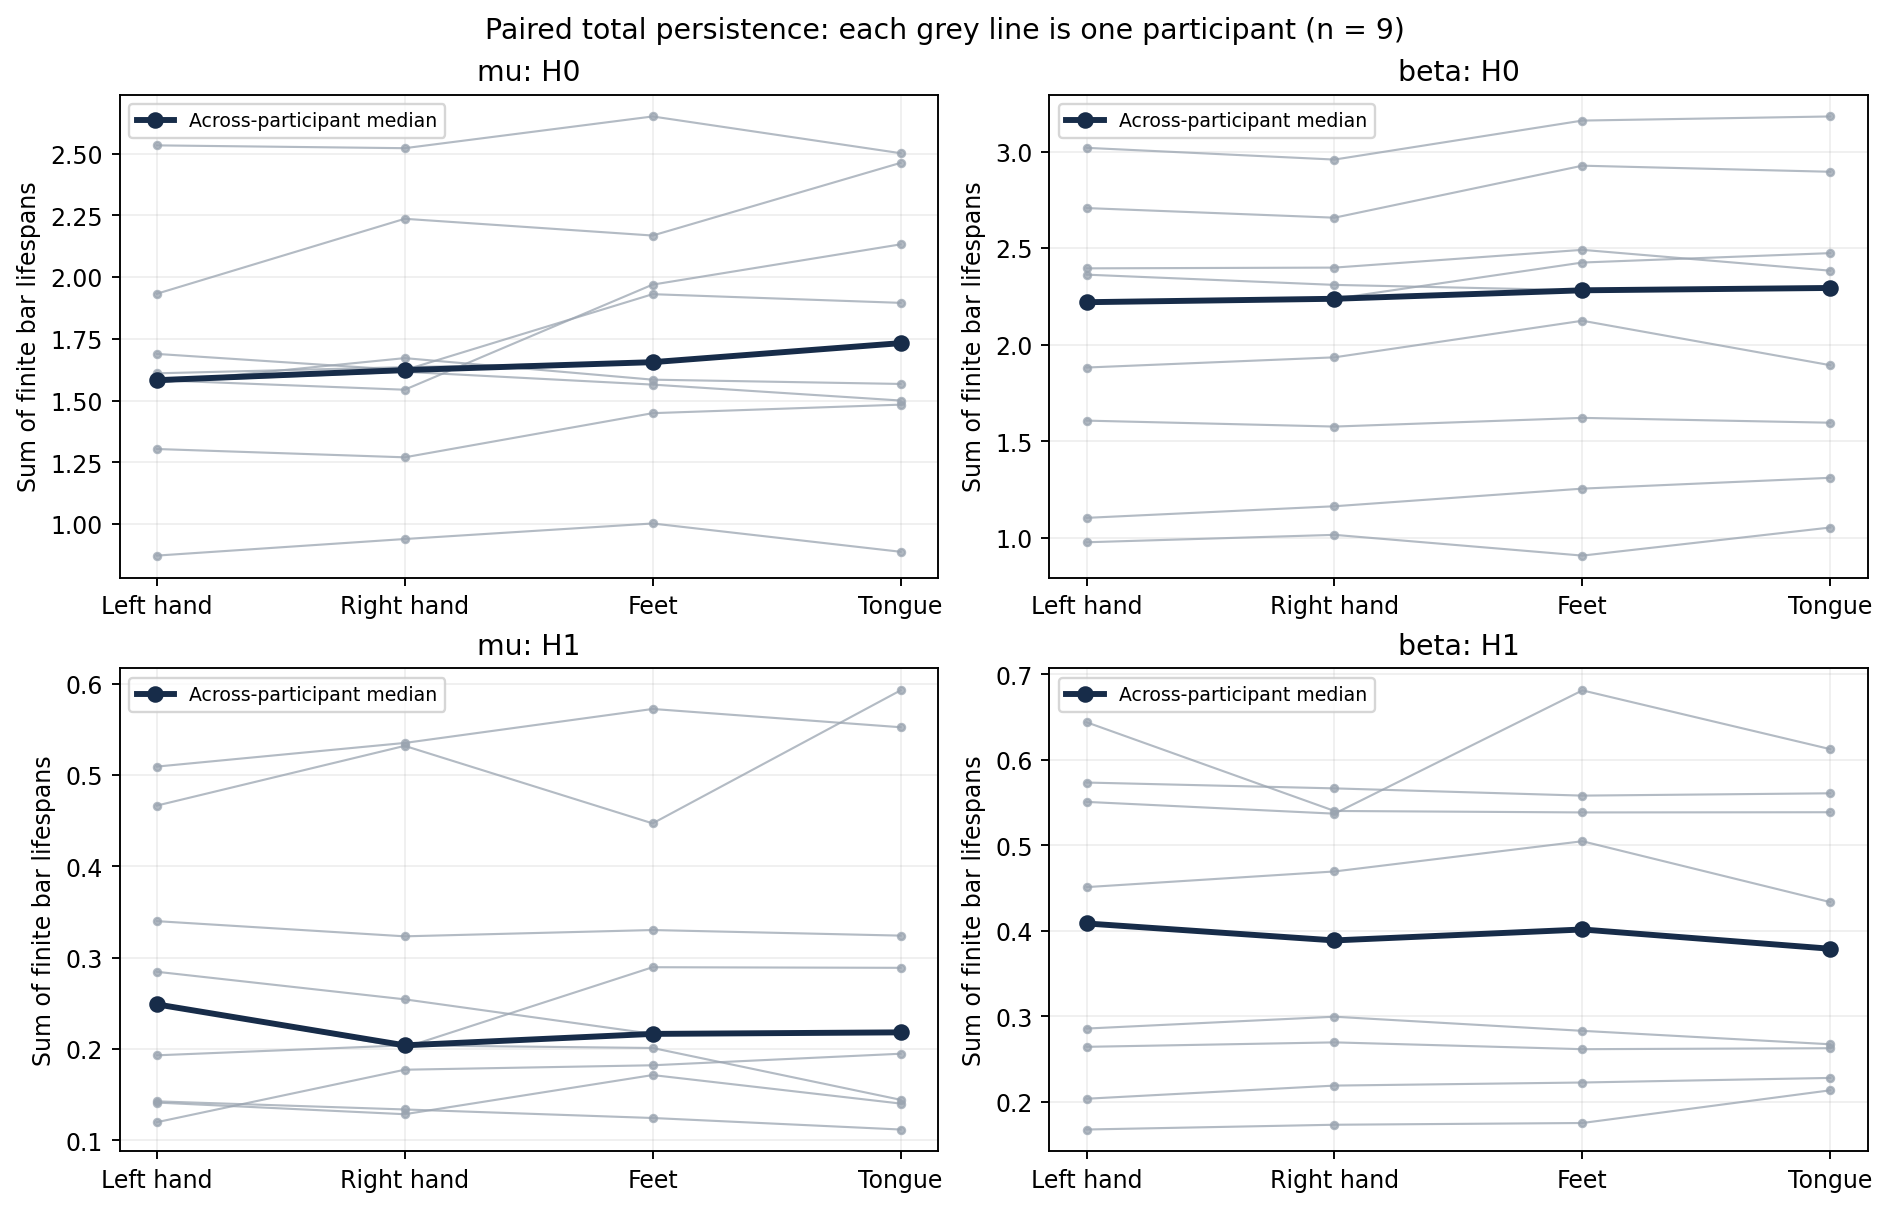

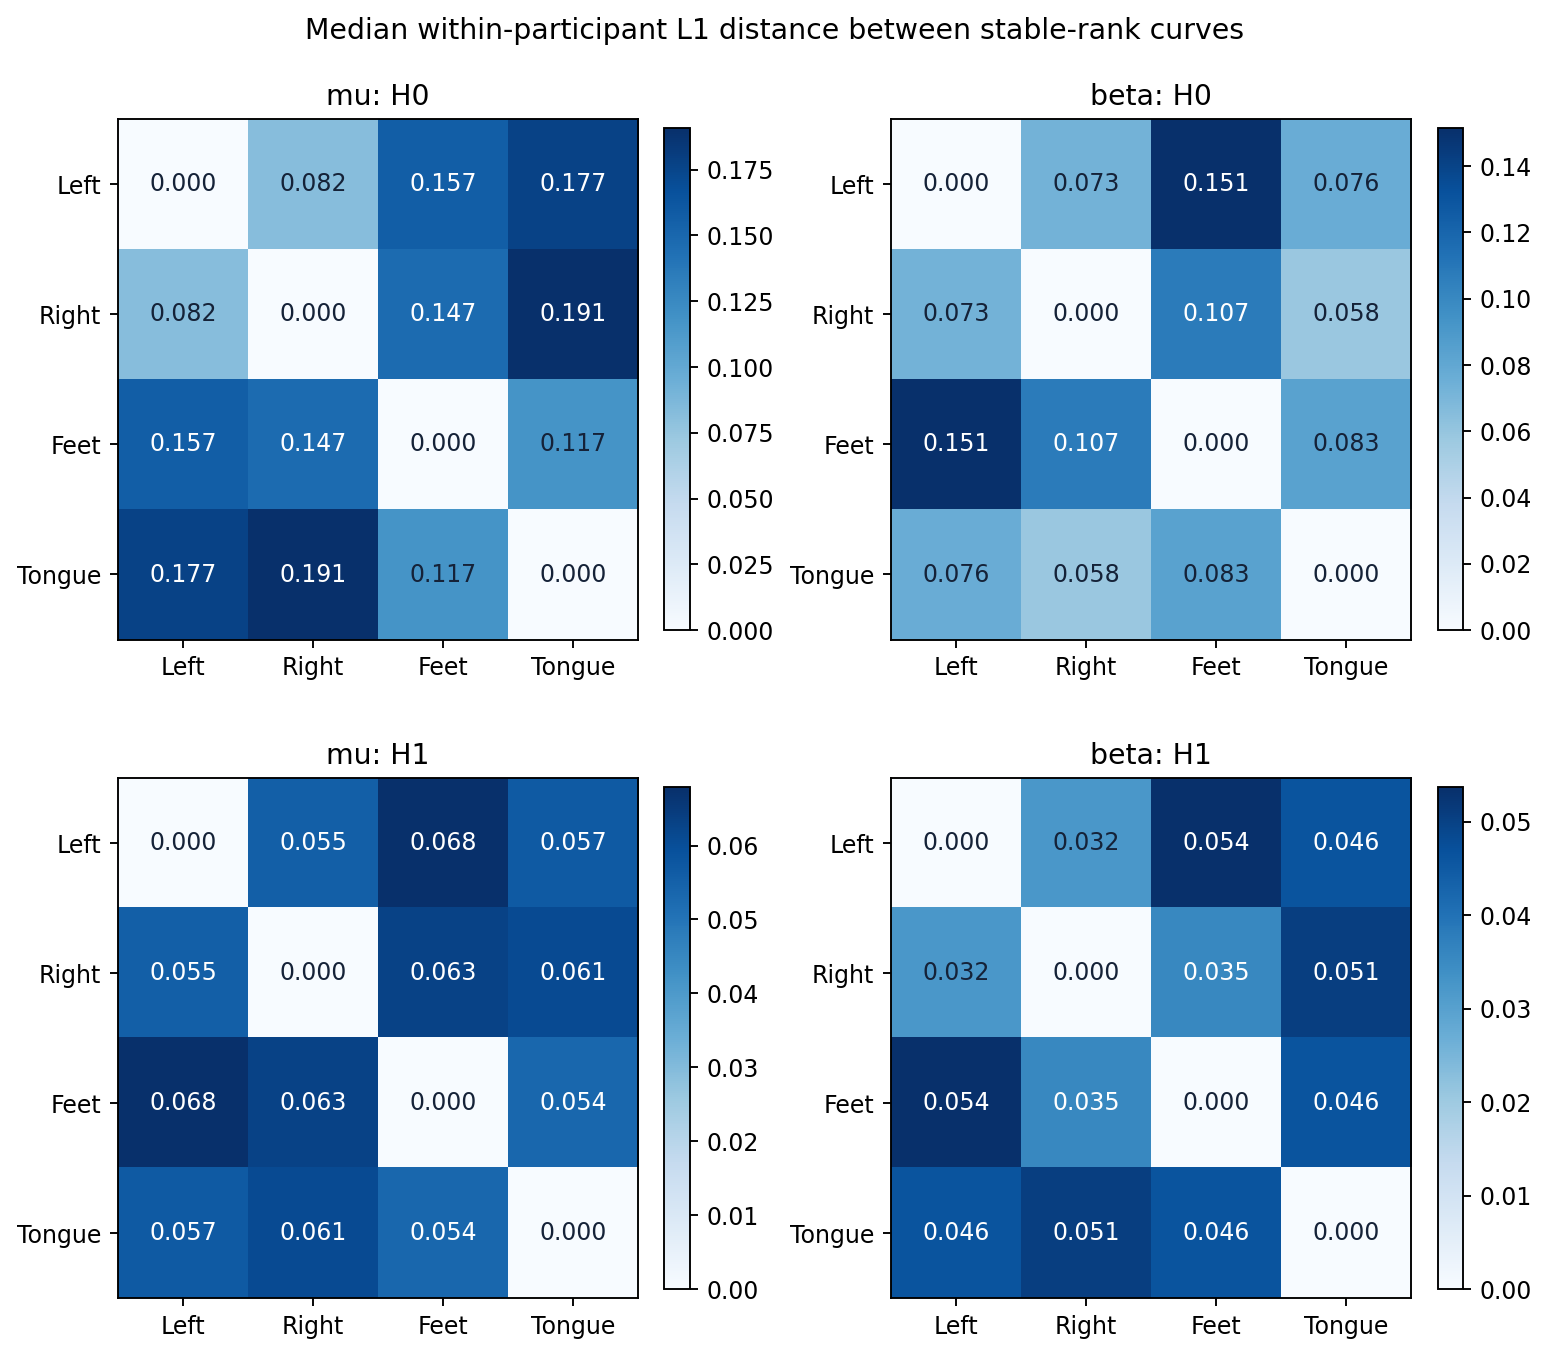

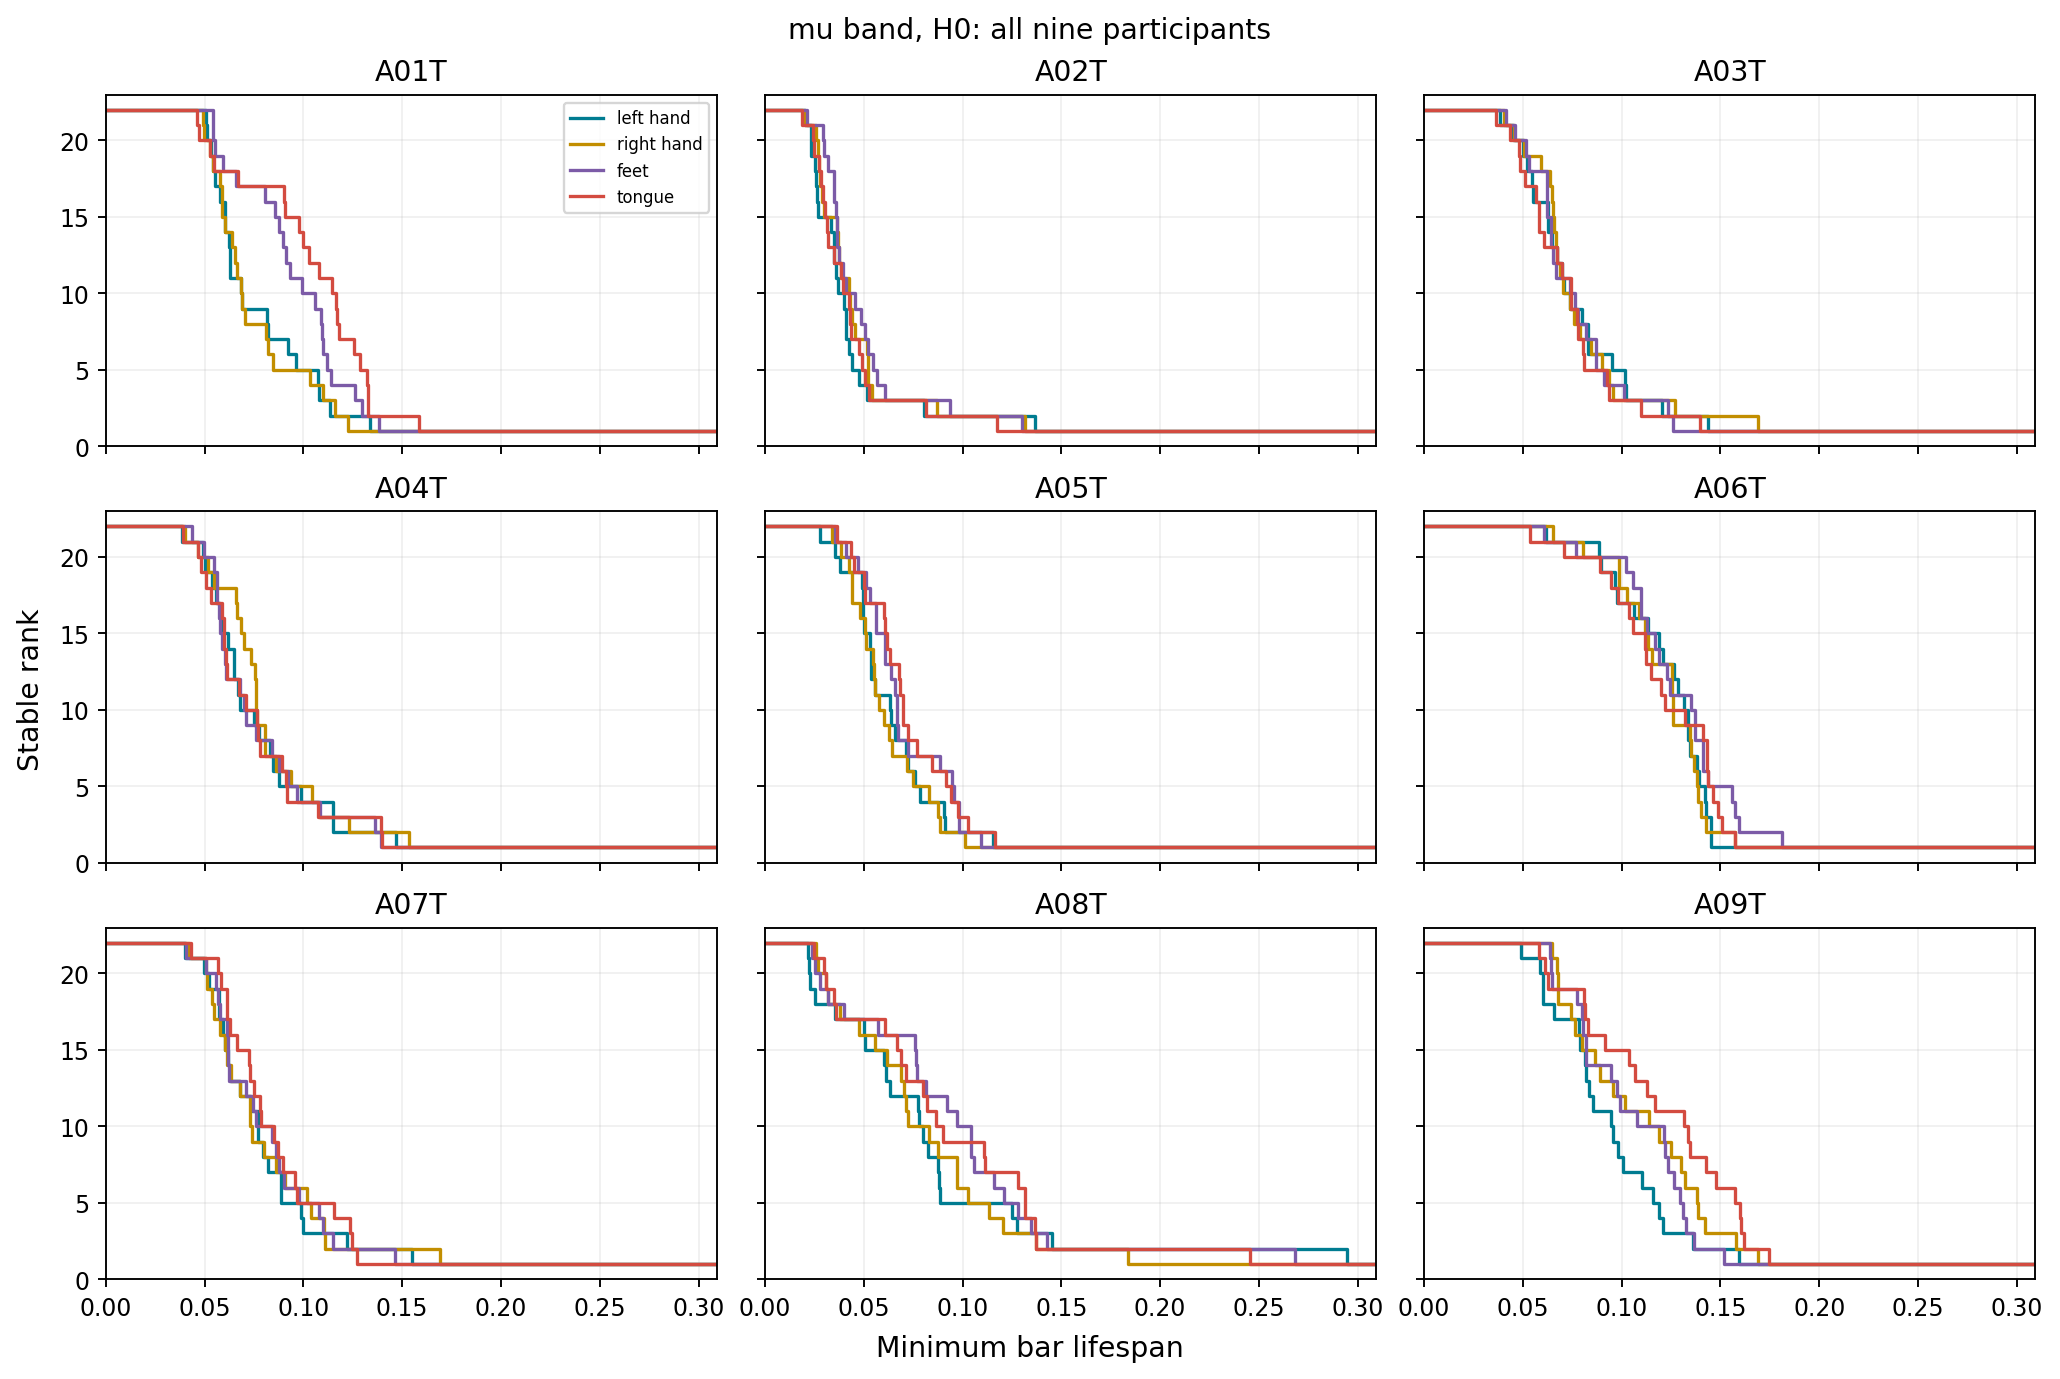

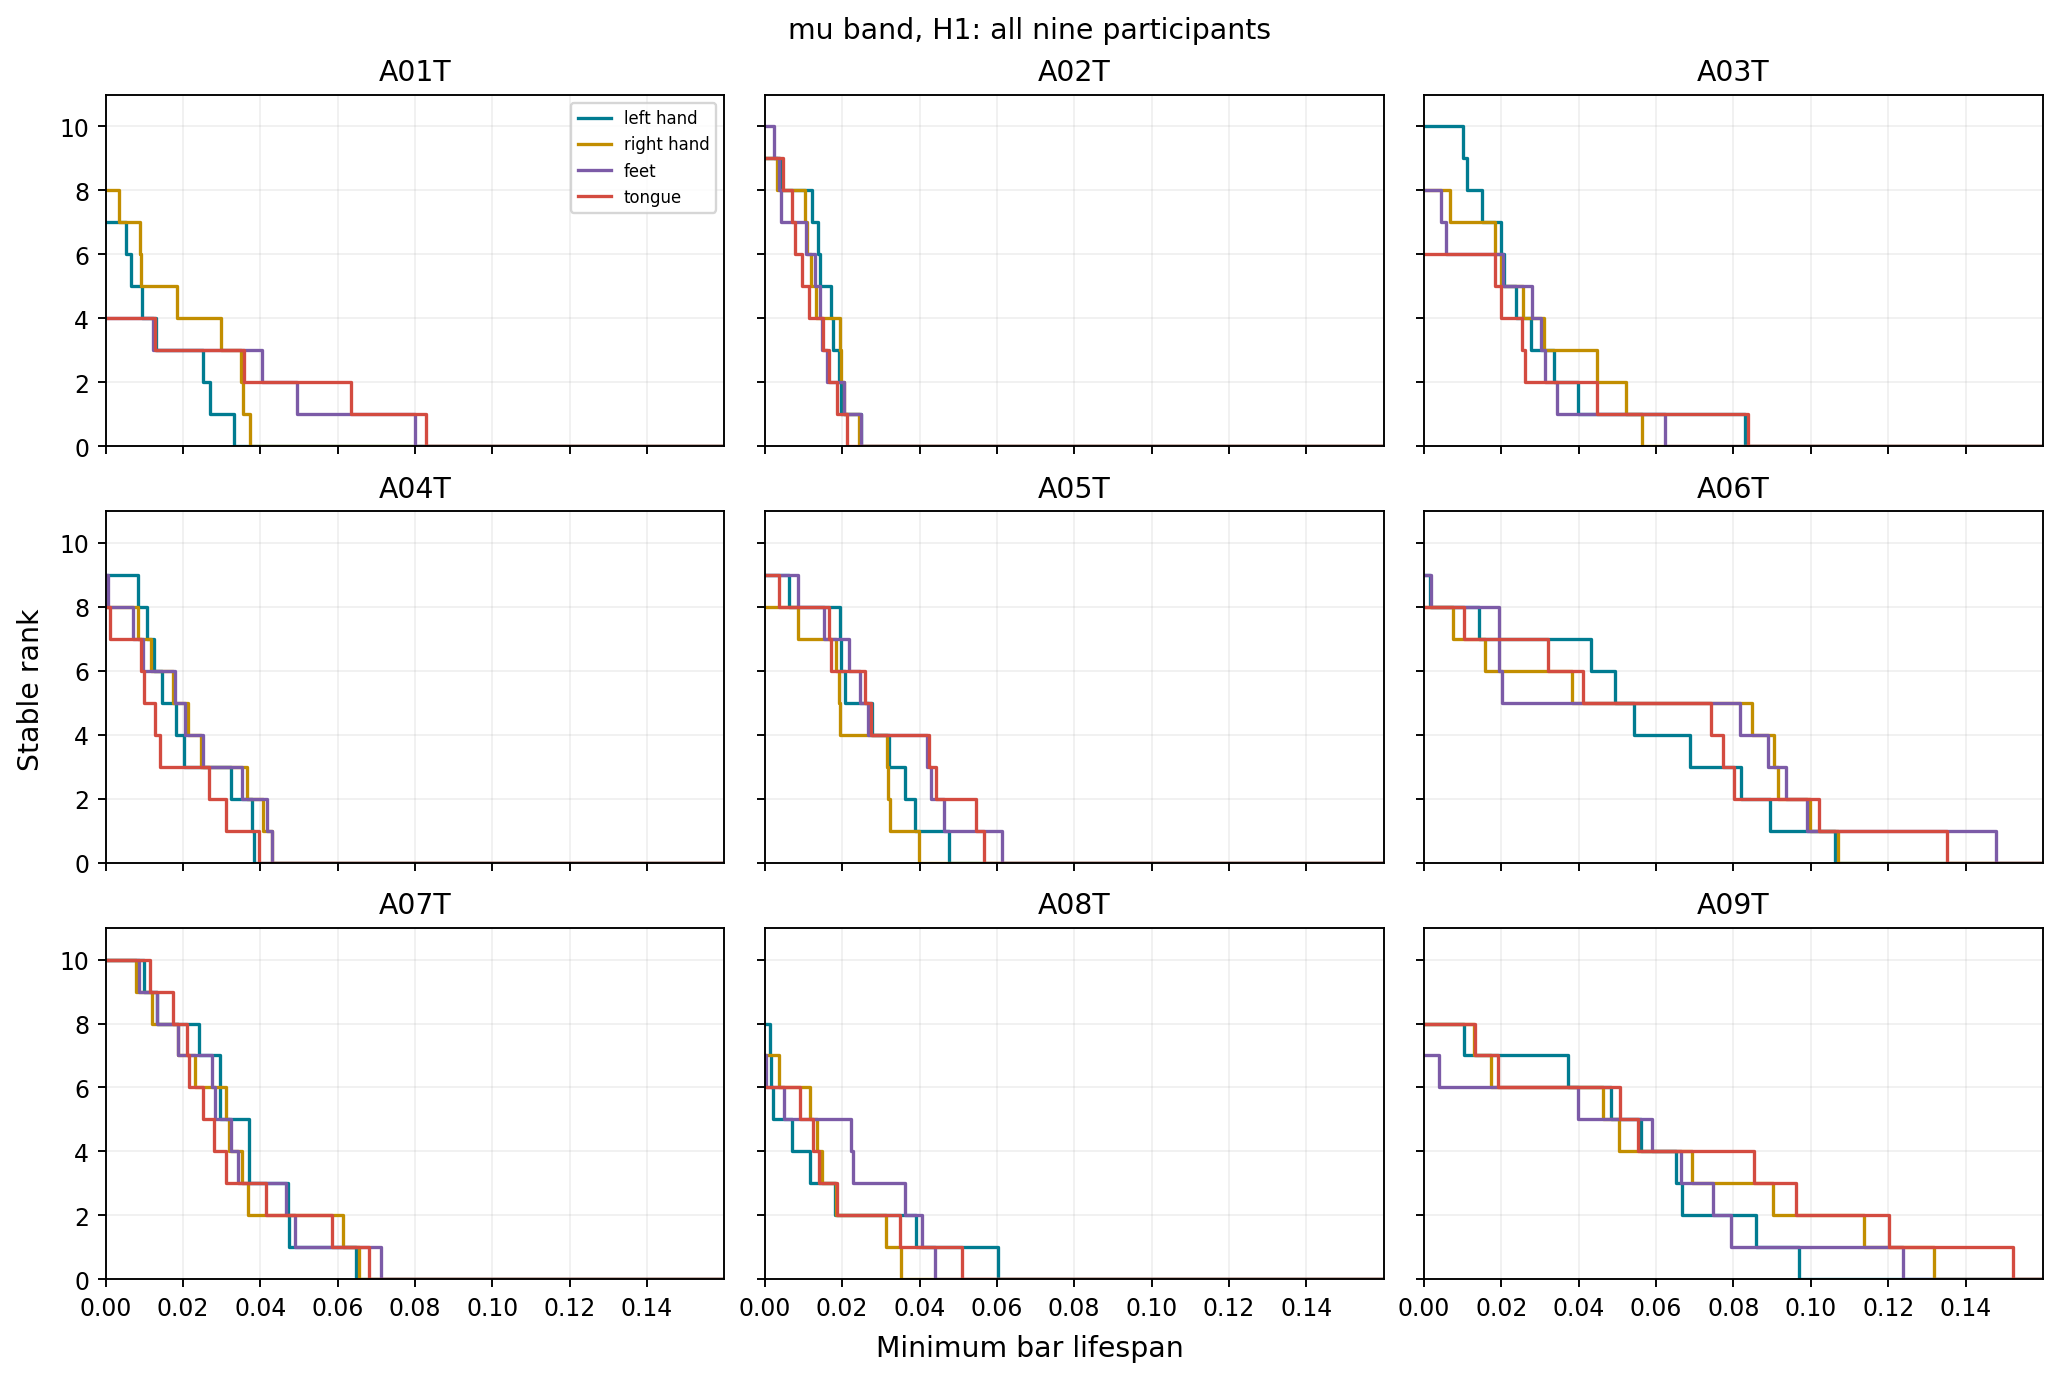

In [9]:
display(omnibus_tests.round(6))
display(pd.read_csv(OUTPUT_DIR / "group_feature_summary.csv").round(4))
from IPython.display import display, Image
for filename in ["group_total_persistence.png", "group_pairwise_distances.png",
                 "all_subjects_mu_H0.png", "all_subjects_mu_H1.png"]:
    display(Image(filename=str(OUTPUT_DIR / filename)))

## What the completed nine-participant analysis found

- **2,328 / 2,592 trials retained**, with 264 dataset-flagged exclusions. The primary balanced analysis uses **2,224 trials**, 49–67 per movement within each participant.
- A01 is reproduced: mu H1 has 7, 8, 4 and 4 bars for left hand, right hand, feet and tongue. The longest loops are longer for feet/tongue in this participant, but this ordering does not consistently generalize.
- For finite total persistence, primary Holm-adjusted permutation p-values are **0.98156 (mu H0), 1.00000 (mu H1), 0.98156 (beta H0), 1.00000 (beta H1)**. None is significant at 0.05. This is insufficient evidence of a consistent movement effect in these scalar summaries, not proof of identical full barcodes.
- The common-count check (49 trials per movement for everyone) gives four adjusted p-values of 1.00000.
- The amplitude rule flags 9 trials across A01/A02/A07. Temporarily removing them causes at most 0.010402 change in one channel-pair distance. This check does not prove the data are artifact-free.
- Trial-selection variation is larger for A06 and A09; min–max shading across selections is not a confidence interval.

The complete report explains how these conclusions follow from the matrices, barcodes, stable ranks and paired participant summaries.


## 10. Inspect any participant
Change `SUBJECT` below to A02T, ..., A09T. The beta all-participant figures and every individual barcode are saved in the results folder.

Trials per movement: 67
Amplitude-review IDs: [[7, 24]]
Left-hand mu distance matrix: (22, 22)
Mu H0 movement-to-movement L1 distances:


,subject,matrix,n_review,mean_change,max_change
0,A01T,left_hand_mu,1,0.000000,0.000000
1,A01T,left_hand_beta,1,0.000000,0.000000
2,A01T,right_hand_mu,1,0.000000,0.000000
3,A01T,right_hand_beta,1,0.000000,0.000000
4,A01T,feet_mu,1,0.000000,0.000000
5,A01T,feet_beta,1,0.000000,0.000000
6,A01T,tongue_mu,1,0.001509,0.006213
7,A01T,tongue_beta,1,0.000843,0.002298


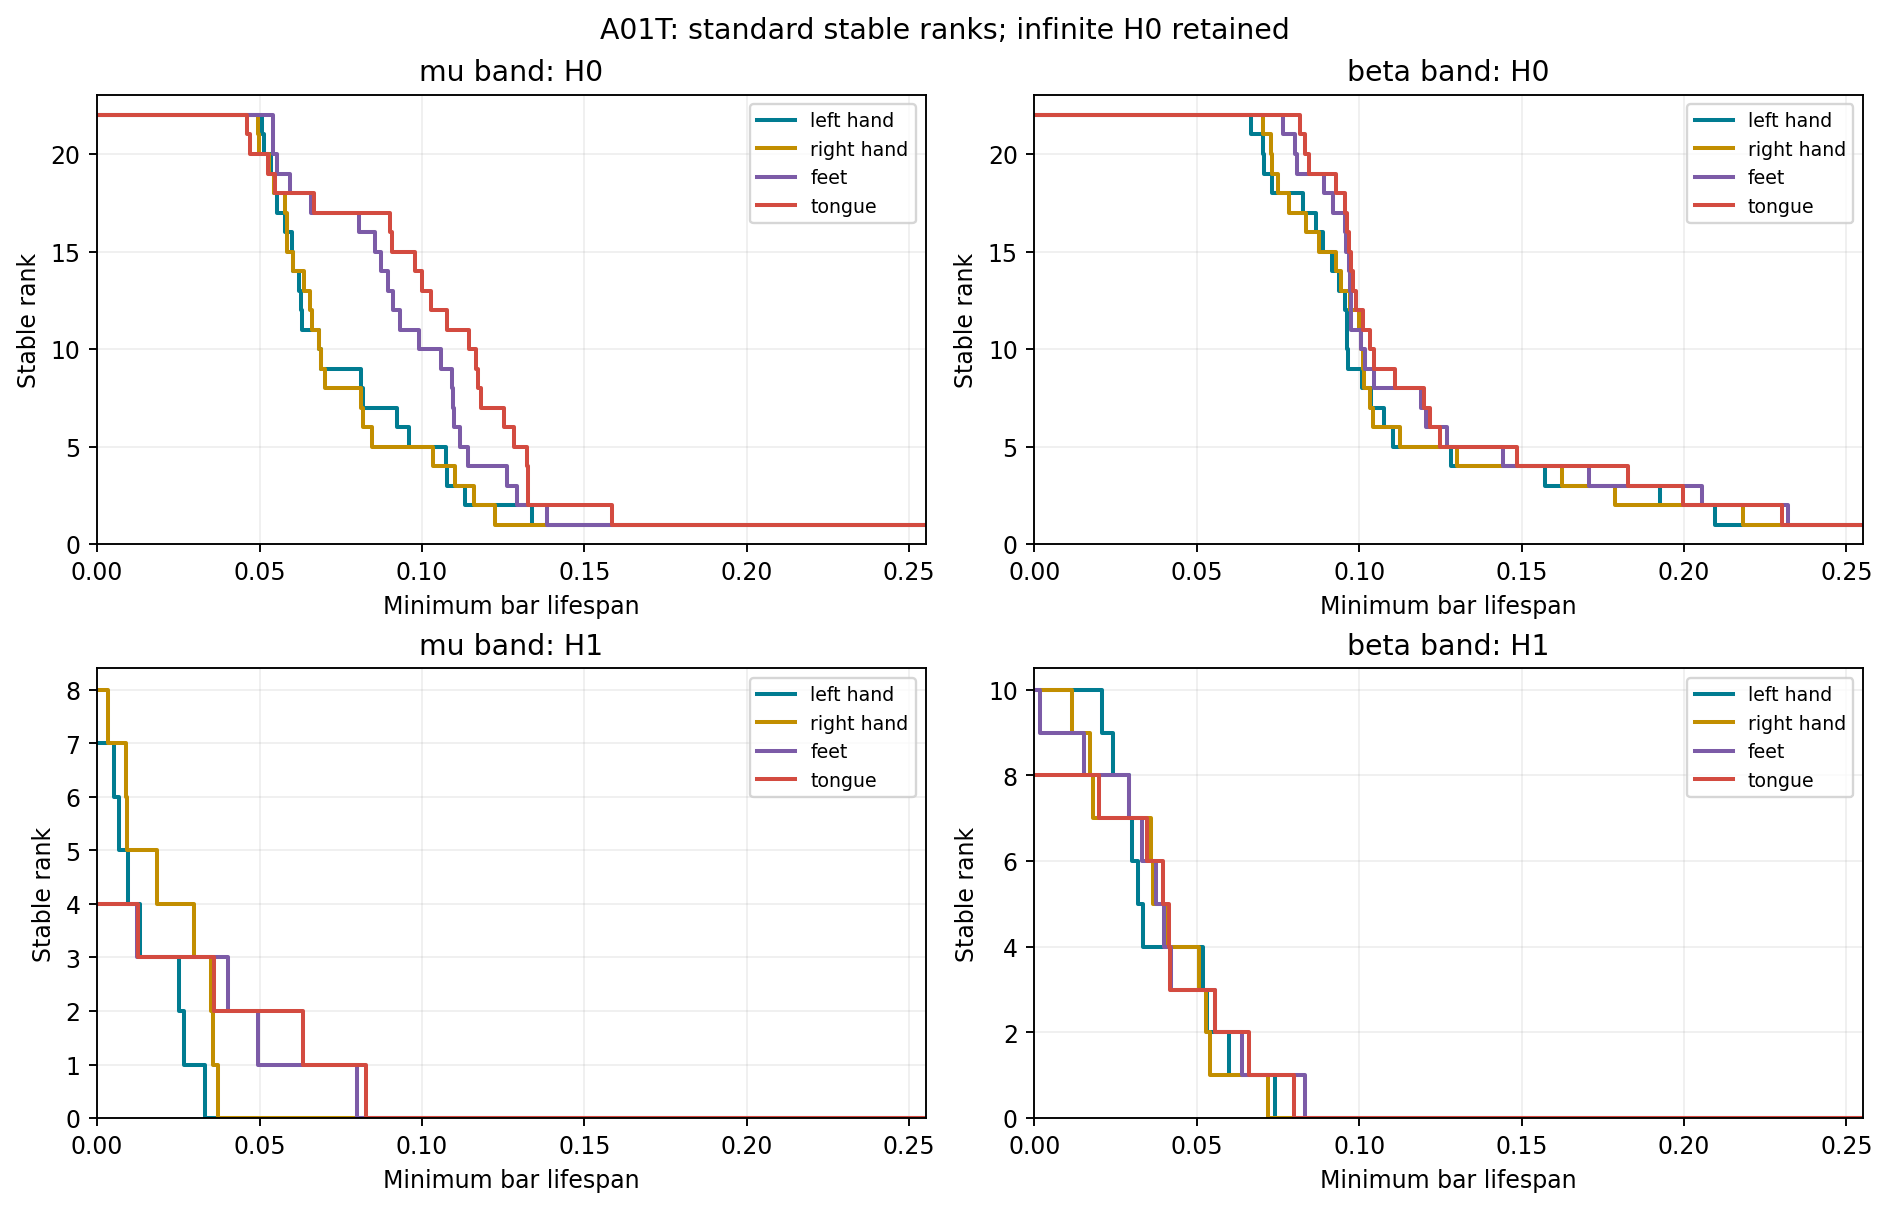

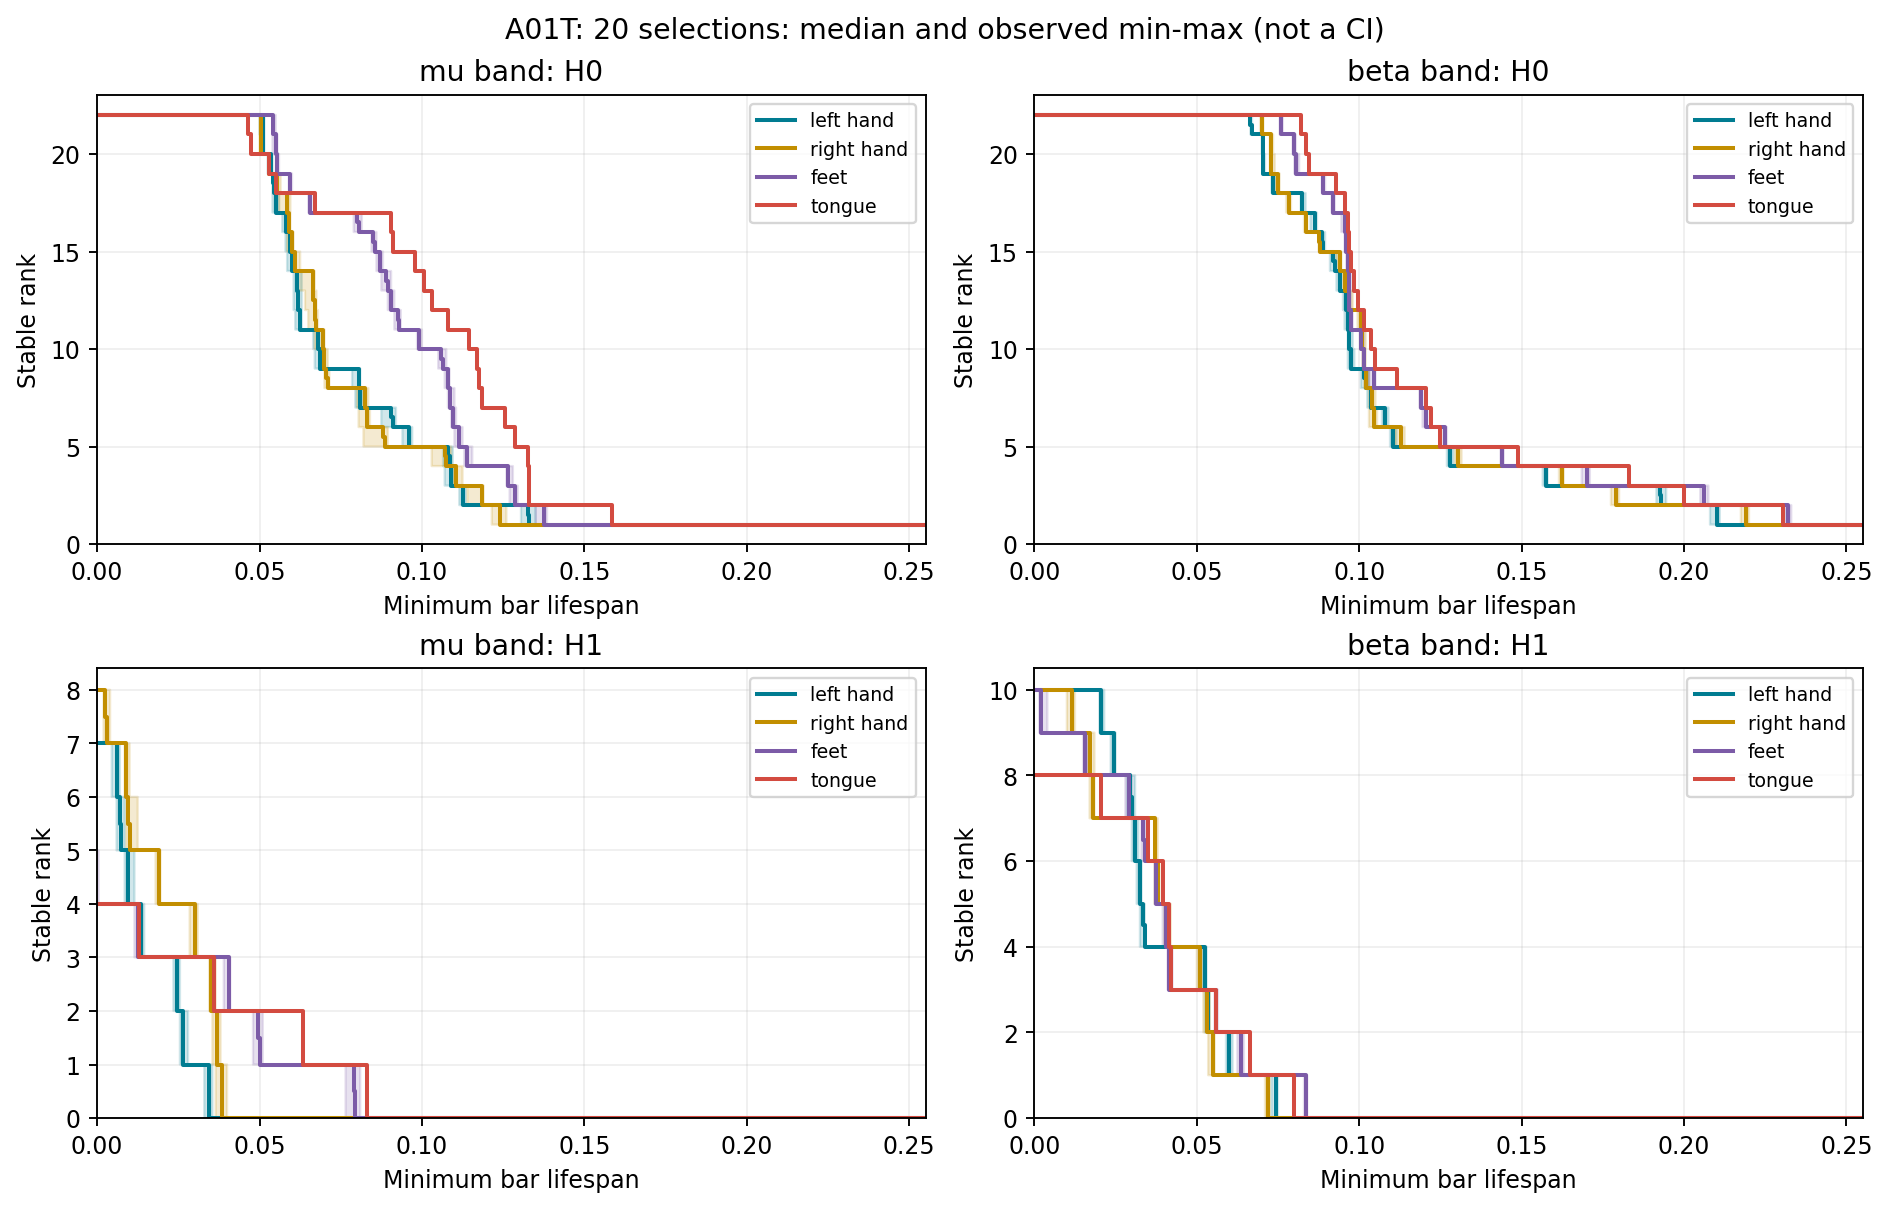

,left_hand,right_hand,feet,tongue
left_hand,0.000000,0.070584,0.387034,0.569898
right_hand,0.070584,0.000000,0.425637,0.600952
feet,0.387034,0.425637,0.000000,0.207648
tongue,0.569898,0.600952,0.207648,0.000000


In [10]:
SUBJECT = "A01T"
subject_folder = OUTPUT_DIR / SUBJECT
settings = json.loads((subject_folder / "settings.json").read_text())
print("Trials per movement:", settings["primary_n_each"])
print("Amplitude-review IDs:", settings["review_original_ids"])
display(pd.read_csv(subject_folder / "amplitude_sensitivity.csv"))
for filename in ["stable_ranks.png", "selection_sensitivity.png"]:
    display(Image(filename=str(subject_folder / filename)))
with np.load(subject_folder / "balanced_topology.npz") as result:
    print("Left-hand mu distance matrix:", result["D_left_hand_mu"].shape)
    print("Mu H0 movement-to-movement L1 distances:")
    display(pd.DataFrame(result["L1_mu_H0"], index=MOVEMENTS, columns=MOVEMENTS))

## 11. Reuse the prepared data or individual matrices
To obtain one participant's retained EEG again:
```python
prepared = prepare_subject(DATA_DIR / "A02T.mat")
X = prepared["X"]       # trials × 1000 time samples × 22 EEG channels
y = prepared["y"]       # 1 left hand, 2 right hand, 3 feet, 4 tongue
trial_ids = prepared["ids"]
```
To load saved topology:
```python
with np.load(OUTPUT_DIR / "A02T" / "balanced_topology.npz") as saved:
    D = saved["D_left_hand_mu"]
    H0 = saved["H0_left_hand_mu"]
    H1 = saved["H1_left_hand_mu"]
```

## 12. Interpretation and limitations
The completed results are discussed in `report/main.tex` and the compiled report. Distinguish: (1) the 22 × 22 channel dissimilarity matrices; (2) four-movement L1 comparison matrices; and (3) before/after amplitude-review changes. These answer different questions.

Nine participants, one training session each, short imagery windows, sensor mixing, reference effects, residual artifacts and subject-specific trial rejection limit generalization. The pipeline does not identify anatomical pathways or causal communication. Stable ranks discard barcode birth positions, and equal ranks need not imply equal full persistence diagrams. The smallest class is unchanged across balanced selections, so narrow ranges can partly reflect the sampling design. The common-count check is one seeded selection, not proof of general robustness.

**References**
- BNCI 001-2014: https://bnci-horizon-2020.eu/database/data-sets
- Brunner et al., Graz data set A description: https://lampx.tugraz.at/~bci/database/001-2014/description.pdf
- El Yaagoubi Bourakna, Chung & Ombao (2022): https://arxiv.org/abs/2204.13799
- Chachólski & Riihimäki (2020): https://arxiv.org/abs/1904.02905
- Supplied SF2956 lecture handouts 9–12 (barcodes, stable ranks, simplicial complexes and homology).
